In [14]:
#!pip install -q dimod dwave-samplers
import dimod
print("dimod:", dimod.__version__)

dimod: 0.12.21


# Annealing

In [35]:
import itertools, time
import numpy as np
import matplotlib.pyplot as plt
from dwave.samplers import SimulatedAnnealingSampler

sampler = SimulatedAnnealingSampler()
np.random.seed(0)

In [26]:
def build_M(h, offsets):
    """Constroi a matriz de tempo de transito, triangular inferior.

    h[j]       : espessura da camada j (m)
    offsets[i] : distancia fonte-detector do par i (m)
    O raio i reflete na base da camada i.
    """
    m = len(h)
    Z = np.cumsum(h)
    M = np.zeros((m, m))
    thetas = np.zeros(m)
    for i in range(m):
        theta = np.arctan((offsets[i] / 2.0) / Z[i])
        thetas[i] = theta
        for j in range(i + 1):
            M[i, j] = 2.0 * h[j] / np.cos(theta)
    return M, thetas

In [27]:
m = 3
h = np.array([500.0, 400.0, 600.0])
v_verdadeiro = np.array([1800.0, 2400.0, 3100.0])
offsets = np.array([600.0, 900.0, 1200.0])
s_verdadeiro = 1.0 / v_verdadeiro

M, thetas = build_M(h, offsets)
t_obs = M @ s_verdadeiro

print("Velocidades do modelo de referência (m/s):", v_verdadeiro)
print("Número de condição de M:", round(np.linalg.cond(M), 2))
print("Tempos de trânsito observados (s):", np.round(t_obs, 5))

Velocidades do modelo de referência (m/s): [1800. 2400. 3100.]
Número de condição de M: 4.2
Tempos de trânsito observados (s): [0.64788 0.99381 1.37428]


## QUBO

In [28]:
def build_A(M, R):
    """Relaciona Mx = Aq, com a coluna i*R+r correspondendo ao bit r da camada i."""
    m, n = M.shape
    A = np.zeros((m, n * R))
    for i in range(n):
        for r in range(R):
            A[:, i * R + r] = M[:, i] * (2.0 ** (-r))
    return A

def qubo_from_A(A, b):
    nq = A.shape[1]
    Q = np.zeros((nq, nq))
    for i in range(nq):
        Q[i, i] = np.sum(A[:, i] * (A[:, i] - 2.0 * b))
    for i in range(nq):
        for j in range(i + 1, nq):
            Q[i, j] = 2.0 * np.sum(A[:, i] * A[:, j])
    return Q, float(b @ b)

def qubo_cost(Q, offset, q):
    q = np.asarray(q, dtype=float)
    return float(q @ Q @ q + offset)

def bits_to_x(q, m, R):
    q = np.asarray(q, dtype=float).reshape(m, R)
    return q @ (2.0 ** (-np.arange(R)))

def brute_force_qubo(Q, offset):
    """Enumeracao exata. Viavel apenas para poucos qubits; serve de referencia."""
    n = Q.shape[0]
    melhor, custo_min = None, np.inf
    for bits in itertools.product([0, 1], repeat=n):
        c = qubo_cost(Q, offset, bits)
        if c < custo_min:
            custo_min, melhor = c, np.array(bits)
    return melhor, custo_min

In [29]:
R = 3
v0 = 2400.0
s0 = np.ones(m) / v0
L = 0.5 * abs(1/1500.0 - 1/4000.0)
ones = np.ones(m)

A = build_A(M, R)
b_vec = (t_obs + L * (M @ ones) - M @ s0) / L
Q, C = qubo_from_A(A, b_vec)

print(f"Número de variáveis binárias: {Q.shape[0]} (m={m} camadas x R={R} bits)")
print(f"Entradas não nulas em Q: {np.count_nonzero(Q)} de {Q.size}")

Número de variáveis binárias: 9 (m=3 camadas x R=3 bits)
Entradas não nulas em Q: 45 de 81


In [30]:
def Q_para_bqm(Q, offset):
    n = Q.shape[0]
    Qd = {(i, i): float(Q[i, i]) for i in range(n)}
    Qd.update({(i, j): float(Q[i, j]) for i in range(n) for j in range(i+1, n) if Q[i, j] != 0})
    return dimod.BinaryQuadraticModel.from_qubo(Qd, offset=offset)


def resolver_por_annealing(Q, offset, num_reads=100, num_sweeps=500, seed=None):
    """Resolve um QUBO por annealing simulado, executado localmente.

    A troca para hardware físico, quando disponível, envolve substituir o
    objeto 'sampler' por um solucionador conectado a um provedor de nuvem;
    a construção do problema (Q_para_bqm) permanece idêntica.
    """
    bqm = Q_para_bqm(Q, offset)
    resultado = sampler.sample(bqm, num_reads=num_reads, num_sweeps=num_sweeps, seed=seed)
    melhor = resultado.first.sample
    n = Q.shape[0]
    return np.array([melhor[i] for i in range(n)])

In [31]:
q_exato, custo_exato = brute_force_qubo(Q, C)
q_annealing = resolver_por_annealing(Q, C, num_reads=200, num_sweeps=500, seed=1)
custo_annealing = qubo_cost(Q, C, q_annealing)

print("Solução exata (enumeração):", q_exato, " custo:", round(custo_exato, 6))
print("Solução por annealing     :", q_annealing, " custo:", round(custo_annealing, 6))
print("Coincidem." if np.array_equal(q_exato, q_annealing) else
      "Divergem (situação pouco frequente neste tamanho de problema).")

Solução exata (enumeração): [1 1 1 1 0 0 0 1 0]  custo: 18865.675223
Solução por annealing     : [1 1 1 1 0 0 0 1 0]  custo: 18865.675223
Coincidem.


In [32]:
def inversao_recursiva(M, t_obs, s0, L, R, solver, n_iter=8, verbose=True):
    m = M.shape[0]
    ones = np.ones(m)
    A = build_A(M, R)
    historico, s_atual, L_atual = [], s0.copy(), float(L)

    for it in range(n_iter):
        b = (t_obs + L_atual * (M @ ones) - M @ s_atual) / L_atual
        Q, off = qubo_from_A(A, b)
        q = solver(Q, off)
        x = bits_to_x(q, m, R)
        s_atual = s_atual + L_atual * (x - ones)
        residuo = float(np.linalg.norm(M @ s_atual - t_obs))
        historico.append({"iter": it + 1, "s": s_atual.copy(), "L": L_atual,
                          "residuo": residuo, "v": 1.0 / s_atual})
        if verbose:
            print(f"  iteração {it+1:2d}  L={L_atual:.2e}  "
                  f"||Ms-t||={residuo:.3e}  v={np.round(1/s_atual,1)}")
        L_atual *= 2.0 ** (-(R - 1))
    return s_atual, historico

## Algoritmo recursivo

In [33]:
print("Inversão recursiva por annealing simulado, execução local:\n")
t_inicio = time.time()
s_final, historico = inversao_recursiva(
    M, t_obs, s0, L, R,
    lambda Q_, o_: resolver_por_annealing(Q_, o_, num_reads=100, num_sweeps=500, seed=1),
    n_iter=8)
tempo_total = time.time() - t_inicio
print(f"\nTempo total: {tempo_total:.2f} s")

v_final = 1.0 / s_final
print(f"\n{'camada':>7}{'v verdadeiro':>15}{'v recuperado':>15}{'erro relativo':>15}")
print("-" * 52)
for j in range(m):
    erro = abs(v_final[j] - v_verdadeiro[j]) / v_verdadeiro[j]
    print(f"{j:>7}{v_verdadeiro[j]:>15.1f}{v_final[j]:>15.2f}{erro:>15.2e}")
print(f"\nErro relativo médio: {np.mean(abs(v_final-v_verdadeiro)/v_verdadeiro):.2e}")

Inversão recursiva por annealing simulado, execução local:

  iteração  1  L=2.08e-04  ||Ms-t||=2.862e-02  v=[1745.5 2400.  3200. ]
  iteração  2  L=5.21e-05  ||Ms-t||=8.905e-03  v=[1786.  2477.4 3072. ]
  iteração  3  L=1.30e-05  ||Ms-t||=2.943e-03  v=[1796.5 2418.9 3103. ]
  iteração  4  L=3.26e-06  ||Ms-t||=5.795e-04  v=[1799.1 2404.7 3095.2]
  iteração  5  L=8.14e-07  ||Ms-t||=1.334e-04  v=[1799.8 2401.2 3099.1]
  iteração  6  L=2.03e-07  ||Ms-t||=4.300e-05  v=[1799.9 2400.3 3099.6]
  iteração  7  L=5.09e-08  ||Ms-t||=8.697e-06  v=[1800.  2400.1 3100. ]
  iteração  8  L=1.27e-08  ||Ms-t||=2.874e-06  v=[1800. 2400. 3100.]

Tempo total: 0.12 s

 camada   v verdadeiro   v recuperado  erro relativo
----------------------------------------------------
      0         1800.0        1800.00       1.91e-06
      1         2400.0        2400.02       7.63e-06
      2         3100.0        3100.00       9.54e-07

Erro relativo médio: 3.50e-06


## Resultados

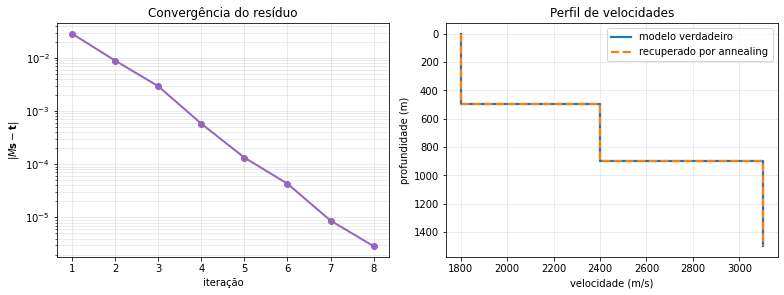

In [34]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4.2))
iters = [d["iter"] for d in historico]

eixos[0].semilogy(iters, [d["residuo"] for d in historico], "o-", lw=2, color="tab:purple")
eixos[0].set_xlabel("iteração"); eixos[0].set_ylabel(r"$\|M\mathbf{s}-\mathbf{t}\|$")
eixos[0].set_title("Convergência do resíduo"); eixos[0].grid(alpha=.3, which="both")

Z_acum = np.concatenate([[0], np.cumsum(h)])
def perfil_degraus(v):
    xs, ys = [], []
    for j in range(len(v)):
        xs += [v[j], v[j]]; ys += [Z_acum[j], Z_acum[j+1]]
    return xs, ys

for vv, rotulo, estilo in [(v_verdadeiro, "modelo verdadeiro", "-"),
                           (v_final, "recuperado por annealing", "--")]:
    xs, ys = perfil_degraus(vv)
    eixos[1].plot(xs, ys, estilo, lw=2.2, label=rotulo)
eixos[1].invert_yaxis()
eixos[1].set_xlabel("velocidade (m/s)"); eixos[1].set_ylabel("profundidade (m)")
eixos[1].set_title("Perfil de velocidades"); eixos[1].legend(); eixos[1].grid(alpha=.3)
plt.tight_layout(); plt.show()